# 05 - Model Evaluation & Model Selection (All Checkpoints)

## Workflow
1. **STEP 1**: Setup environment (local or Google Colab) and register datasets
2. **STEP 2**: Discover all saved checkpoints (`.pth` / `.pt`) from outputs on Google Drive
3. **STEP 3**: Run full COCO evaluation for every checkpoint on validation set
4. **STEP 4**: Build leaderboard, pick the best model automatically
5. **STEP 5**: Run visual inference with the selected best model

## Colab paths (default)
- Project root: `/content/drive/MyDrive/INSEG_PRO`
- Models root: `/content/drive/MyDrive/INSEG_PRO/outputs`

You can change the root path in STEP 1 if your Drive structure is different.

---

Questions auxquelles on va repondre:
- Quel checkpoint est le meilleur globalement?
- Quel score AP/AP50/AP75 est le plus eleve pour bbox et masks?
- Quel modele doit etre garde comme modele final?

In [ ]:
import os
import re
import sys
import json
from pathlib import Path
import torch
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Detect environment
IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=False)
    PROJECT_DIR = Path('/content/drive/MyDrive/INSEG_PRO')
    if not PROJECT_DIR.exists():
        raise FileNotFoundError(
            f'Google Drive project folder not found: {PROJECT_DIR}. '
            'Update PROJECT_DIR in this cell to your actual path.'
        )
else:
    PROJECT_DIR = Path('/home/rachidjunior/VS_Code/INSEG_PRO')

DATA_DIR = PROJECT_DIR / 'data' / 'raw'
OUTPUTS_ROOT = PROJECT_DIR / 'outputs'

# Candidate model folders (searched recursively later)
MODEL_SEARCH_DIRS = [
    OUTPUTS_ROOT,
    OUTPUTS_ROOT / 'mask_rcnn_cityscapes_colab',
    OUTPUTS_ROOT / 'mask_rcnn_cityscapes',
]

# Add project modules to path
sys.path.insert(0, str(PROJECT_DIR / 'data'))
sys.path.insert(0, str(PROJECT_DIR))

print('=' * 70)
print('SETUP - EVALUATION (LOCAL/COLAB)')
print('=' * 70)
print(f'Running on Colab: {IN_COLAB}')
print(f'Project: {PROJECT_DIR}')
print(f'Data: {DATA_DIR}')
print(f'Outputs root: {OUTPUTS_ROOT}')
print(f'GPU available: {torch.cuda.is_available()}')

Mounted at /content/drive
SETUP - EVALUATION (LOCAL/COLAB)
Running on Colab: True
Project: /content/drive/MyDrive/INSEG_PRO
Data: /content/drive/MyDrive/INSEG_PRO/data/raw
Outputs root: /content/drive/MyDrive/INSEG_PRO/outputs
GPU available: True


In [ ]:
# Fixed path layout for your Drive structure.
PROJECT_DIR = Path('/content/drive/MyDrive/INSEG_PRO')
CODE_DIR = PROJECT_DIR / 'code'

if not PROJECT_DIR.exists():
    raise FileNotFoundError(
        f'Project folder not found at: {PROJECT_DIR}. '
        'Upload/copy INSEG_PRO to Drive and update PROJECT_DIR.'
    )

if not CODE_DIR.exists():
    raise FileNotFoundError(
        f'Code folder not found at: {CODE_DIR}. '
        'Expected INSEG_PRO/code in Google Drive.'
    )

# Your dataset loader is at INSEG_PRO/code/dataset_loader.py.
DATASET_LOADER_PATH = CODE_DIR / 'dataset_loader.py'
if not DATASET_LOADER_PATH.exists():
    raise FileNotFoundError(
        f'dataset_loader.py not found at: {DATASET_LOADER_PATH}'
    )

%cd {CODE_DIR}
if str(CODE_DIR) not in sys.path:
    sys.path.insert(0, str(CODE_DIR))

print('Project directory:', PROJECT_DIR)
print('Code directory   :', CODE_DIR)
print('dataset_loader   :', DATASET_LOADER_PATH)
print('requirements in code dir   :', (CODE_DIR / 'requirements.txt').exists())
print('requirements in project dir:', (PROJECT_DIR / 'requirements.txt').exists())

/content/drive/MyDrive/INSEG_PRO/code
Project directory: /content/drive/MyDrive/INSEG_PRO
Code directory   : /content/drive/MyDrive/INSEG_PRO/code
dataset_loader   : /content/drive/MyDrive/INSEG_PRO/code/dataset_loader.py
requirements in code dir   : False
requirements in project dir: True


In [ ]:
print('=' * 70)
print('STEP 2 - INSTALL DEPENDENCIES')
print('=' * 70)

import sys
import site
import pkgutil
import subprocess
import importlib.machinery
from pathlib import Path

# Compatibility shims for old pkg_resources implementations on newer Python.
if not hasattr(pkgutil, 'ImpImporter'):
    pkgutil.ImpImporter = pkgutil.zipimporter
if not hasattr(importlib.machinery.FileFinder, 'find_module'):
    def _ff_find_module(self, fullname):
        spec = self.find_spec(fullname)
        return spec.loader if spec else None
    importlib.machinery.FileFinder.find_module = _ff_find_module

# Prefer /usr/local site-packages over distro packages.
for p in reversed([x for x in site.getsitepackages() if x.startswith('/usr/local')]):
    if p in sys.path:
        sys.path.remove(p)
    sys.path.insert(0, p)

REQ_FILE_CODE = CODE_DIR / 'requirements.txt'
REQ_FILE_PROJECT = PROJECT_DIR / 'requirements.txt'
REQ_FILE = REQ_FILE_CODE if REQ_FILE_CODE.exists() else REQ_FILE_PROJECT

def run_pip(args):
    cmd = [sys.executable, '-m', 'pip'] + args
    print('Running:', ' '.join(cmd))
    subprocess.check_call(cmd)

# Bootstrap packaging tools.
run_pip(['install', '-q', '--upgrade', 'pip', 'wheel', 'setuptools>=75.0.0', 'packaging', 'jedi'])

installed_from_requirements = False
if REQ_FILE.exists():
    print(f'Using requirements file: {REQ_FILE}')
    try:
        run_pip(['install', '-q', '-r', str(REQ_FILE)])
        installed_from_requirements = True
    except subprocess.CalledProcessError:
        print('requirements.txt install failed, switching to fallback dependency set...')
else:
    print('No requirements.txt found in code/ or project root.')

if not installed_from_requirements:
    fallback_packages = [
        'torch>=2.0.0',
        'torchvision>=0.15.0',
        'torchaudio>=2.0.0',
        'opencv-python>=4.8.0',
        'Pillow>=10.0.0',
        'albumentations>=1.3.0',
        'numpy>=1.24.0',
        'pandas>=2.0.0',
        'matplotlib>=3.7.0',
        'seaborn>=0.12.0',
        'tqdm>=4.65.0',
        'pyyaml>=6.0',
        'pycocotools>=2.0.0',
        'ipywidgets>=8.0.0'
    ]
    run_pip(['install', '-q', *fallback_packages])

# Install Detectron2.
run_pip(['install', '-q', '--no-build-isolation', 'git+https://github.com/facebookresearch/detectron2.git'])

# Re-apply shims before import checks.
if not hasattr(pkgutil, 'ImpImporter'):
    pkgutil.ImpImporter = pkgutil.zipimporter
if not hasattr(importlib.machinery.FileFinder, 'find_module'):
    def _ff_find_module(self, fullname):
        spec = self.find_spec(fullname)
        return spec.loader if spec else None
    importlib.machinery.FileFinder.find_module = _ff_find_module

import detectron2
from detectron2 import model_zoo
print('Detectron2 installed:', detectron2.__version__)
print('Detectron2 import test: OK')

STEP 2 - INSTALL DEPENDENCIES
Running: /usr/bin/python3 -m pip install -q --upgrade pip wheel setuptools>=75.0.0 packaging jedi
Using requirements file: /content/drive/MyDrive/INSEG_PRO/requirements.txt
Running: /usr/bin/python3 -m pip install -q -r /content/drive/MyDrive/INSEG_PRO/requirements.txt
Running: /usr/bin/python3 -m pip install -q --no-build-isolation git+https://github.com/facebookresearch/detectron2.git
Detectron2 installed: 0.6
Detectron2 import test: OK


In [ ]:
from detectron2 import model_zoo
from detectron2.config import get_cfg
from detectron2.engine import DefaultPredictor, DefaultTrainer
from detectron2.evaluation import COCOEvaluator, inference_on_dataset
from detectron2.data import build_detection_test_loader, MetadataCatalog
from detectron2.utils.visualizer import Visualizer

import importlib
import pkgutil
import importlib.machinery

# Safety patches for Colab
if not hasattr(pkgutil, 'ImpImporter'):
    pkgutil.ImpImporter = pkgutil.zipimporter
if not hasattr(importlib.machinery.FileFinder, 'find_module'):
    def _ff_find_module(self, fullname):
        spec = self.find_spec(fullname)
        return spec.loader if spec else None
    importlib.machinery.FileFinder.find_module = _ff_find_module

# Load dataset
print('\n' + '=' * 70)
print('Loading Dataset Loader...')
print('=' * 70)

try:
    dataset_loader = importlib.import_module('dataset_loader')
    print(f'✓ Dataset loader imported from: {dataset_loader.__file__}')
except ModuleNotFoundError as e:
    print(f'✗ Error: Could not find dataset_loader.py')
    print(f'  Current sys.path:')
    for p in sys.path[:5]:
        print(f'    - {p}')
    raise

register_cityscapes_dataset = dataset_loader.register_cityscapes_dataset
CITYSCAPES_THING_CLASSES = dataset_loader.CITYSCAPES_THING_CLASSES

# Register datasets
print(f'\nRegistering Cityscapes datasets from: {DATA_DIR}')
try:
    train_dataset_name, train_dicts, _ = register_cityscapes_dataset(DATA_DIR, split='train')
    val_dataset_name, val_dicts, _ = register_cityscapes_dataset(DATA_DIR, split='val')

    print(f'✓ Datasets registered successfully!')
    print(f'  Train set: {len(train_dicts)} images')
    print(f'  Val set: {len(val_dicts)} images')
    print(f'  Classes: {len(CITYSCAPES_THING_CLASSES)} ({CITYSCAPES_THING_CLASSES[:3]}...)')
except FileNotFoundError as e:
    print(f'✗ Error: Dataset files not found')
    print(f'  Data directory: {DATA_DIR}')
    print(f'  Exists: {DATA_DIR.exists()}')
    if DATA_DIR.exists():
        print(f'  Contents: {list(DATA_DIR.parent.iterdir())[:5]}')
    raise



Loading Dataset Loader...
✓ Dataset loader imported from: /content/drive/MyDrive/INSEG_PRO/code/dataset_loader.py

Registering Cityscapes datasets from: /content/drive/MyDrive/INSEG_PRO/data/raw
✓ Datasets registered successfully!
  Train set: 935 images
  Val set: 0 images
  Classes: 8 (['person', 'rider', 'car']...)


In [ ]:
print('=' * 70)
print('ENVIRONMENT CHECK')
print('=' * 70)

OUTPUT_DIR = PROJECT_DIR / 'outputs' / 'mask_rcnn_cityscapes_colab'
print(f'\n📁 Directory Structure:')
print(f'  PROJECT_DIR exists: {PROJECT_DIR.exists()}')
print(f'  DATA_DIR exists: {DATA_DIR.exists()}')
print(f'  OUTPUT_DIR exists: {OUTPUT_DIR.exists()}')

if DATA_DIR.exists():
    gtFine_exists = (DATA_DIR / 'gtFine').exists()
    leftImg_exists = (DATA_DIR / 'leftImg8bit').exists()
    print(f'  gtFine directory: {gtFine_exists}')
    print(f'  leftImg8bit directory: {leftImg_exists}')

print(f'\n📦 Python Path (first 3):')
for i, p in enumerate(sys.path[:3]):
    dataset_loader_check = (Path(p) / 'dataset_loader.py').exists()
    print(f'  [{i}] {p}')
    print(f'      dataset_loader.py present: {dataset_loader_check}')

print(f'\n✓ Environment check complete')


ENVIRONMENT CHECK

📁 Directory Structure:
  PROJECT_DIR exists: True
  DATA_DIR exists: True
  OUTPUT_DIR exists: True
  gtFine directory: True
  leftImg8bit directory: True

📦 Python Path (first 3):
  [0] /usr/local/lib/python3.12/dist-packages
      dataset_loader.py present: False
  [1] /content/drive/MyDrive/INSEG_PRO/code
      dataset_loader.py present: True
  [2] /content/drive/MyDrive/INSEG_PRO
      dataset_loader.py present: False

✓ Environment check complete


In [ ]:
print('=' * 70)
print('STEP 1 - DISCOVER ALL SAVED CHECKPOINTS')
print('=' * 70)

if not OUTPUTS_ROOT.exists():
    raise FileNotFoundError(f'Outputs directory not found: {OUTPUTS_ROOT}')

# Search for all checkpoints recursively
patterns = ['**/model_*.pth', '**/model_*.pt', '**/model_final.pth', '**/model_final.pt']
ckpt_set = set()
for pattern in patterns:
    for path in OUTPUTS_ROOT.glob(pattern):
        if path.is_file():
            ckpt_set.add(path.resolve())

checkpoint_candidates = list(ckpt_set)

def checkpoint_sort_key(path: Path):
    stem = path.stem.lower()
    if stem == 'model_final':
        return (2, 10**12, path.name)
    match = re.search(r'(\d+)$', stem)
    iter_num = int(match.group(1)) if match else -1
    return (1, iter_num, path.name)

checkpoint_candidates = sorted(checkpoint_candidates, key=checkpoint_sort_key)

if not checkpoint_candidates:
    raise FileNotFoundError(
        f'No checkpoint file found under {OUTPUTS_ROOT}. '
        'Expected files like model_0005999.pth or model_final.pth'
    )

print(f'Found {len(checkpoint_candidates)} checkpoints:')
for i, ckpt in enumerate(checkpoint_candidates, 1):
    print(f'  [{i:02d}] {ckpt}')

# Metric used to choose the best model
SELECTION_METRIC = 'segm_AP'  # options: bbox_AP, bbox_AP50, bbox_AP75, segm_AP, segm_AP50, segm_AP75

# Keep a default checkpoint for optional quick visualization cell
DEFAULT_CHECKPOINT = checkpoint_candidates[-1]
print(f'\nDefault checkpoint for quick viz: {DEFAULT_CHECKPOINT.name}')
print(f'Model selection metric: {SELECTION_METRIC}')

STEP 1 - DISCOVER ALL SAVED CHECKPOINTS
Found 32 checkpoints:
  [01] /content/drive/MyDrive/INSEG_PRO/outputs/mask_rcnn_cityscapes_colab/model_0000299.pth
  [02] /content/drive/MyDrive/INSEG_PRO/outputs/mask_rcnn_cityscapes_colab/model_0000599.pth
  [03] /content/drive/MyDrive/INSEG_PRO/outputs/mask_rcnn_cityscapes_colab/model_0000899.pth
  [04] /content/drive/MyDrive/INSEG_PRO/outputs/mask_rcnn_cityscapes_colab/model_0001199.pth
  [05] /content/drive/MyDrive/INSEG_PRO/outputs/mask_rcnn_cityscapes_colab/model_0001499.pth
  [06] /content/drive/MyDrive/INSEG_PRO/outputs/mask_rcnn_cityscapes_colab/model_0001799.pth
  [07] /content/drive/MyDrive/INSEG_PRO/outputs/mask_rcnn_cityscapes_colab/model_0002099.pth
  [08] /content/drive/MyDrive/INSEG_PRO/outputs/mask_rcnn_cityscapes_colab/model_0002399.pth
  [09] /content/drive/MyDrive/INSEG_PRO/outputs/mask_rcnn_cityscapes_colab/model_0002699.pth
  [10] /content/drive/MyDrive/INSEG_PRO/outputs/mask_rcnn_cityscapes_colab/model_0002999.pth
  [11] /

In [ ]:
print('=' * 70)
print('STEP 4 - VISUAL INFERENCE WITH SELECTED MODEL')
print('=' * 70)

# Use the best model selected by STEP 3 when available
if 'BEST_MODEL_PATH' in globals():
    viz_checkpoint = BEST_MODEL_PATH
    print(f'Using BEST_MODEL_PATH from leaderboard: {viz_checkpoint.name}')
else:
    viz_checkpoint = DEFAULT_CHECKPOINT
    print('BEST_MODEL_PATH not found yet. Run STEP 3 first for automatic selection.')
    print(f'Fallback checkpoint: {viz_checkpoint.name}')

cfg_viz = get_cfg()
cfg_viz.merge_from_file(
    model_zoo.get_config_file('COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml')
)
cfg_viz.DATASETS.TEST = (val_dataset_name,)
cfg_viz.MODEL.ROI_HEADS.NUM_CLASSES = len(CITYSCAPES_THING_CLASSES)
cfg_viz.MODEL.WEIGHTS = str(viz_checkpoint)
cfg_viz.MODEL.DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

predictor = DefaultPredictor(cfg_viz)

viz_tag = viz_checkpoint.stem
viz_dir = OUTPUTS_ROOT / f'inference_viz_{viz_tag}'
viz_dir.mkdir(parents=True, exist_ok=True)

results_summary = []
for idx, d in enumerate(val_dicts[:5]):
    img = cv2.imread(d['file_name'])
    if img is None:
        print(f'[{idx}] Could not load: {d["file_name"]}')
        continue

    outputs = predictor(img)
    instances = outputs['instances'].to('cpu')

    v = Visualizer(img[:, :, ::-1], MetadataCatalog.get(val_dataset_name), scale=0.8)
    v = v.draw_instance_predictions(instances)
    result_img = v.get_image()[:, :, ::-1]

    output_path = viz_dir / f'inference_{idx:02d}.jpg'
    cv2.imwrite(str(output_path), result_img)

    n_detections = len(instances)
    results_summary.append({
        'image_idx': idx,
        'file': Path(d['file_name']).name,
        'detections': n_detections,
        'saved_to': output_path.name
    })

    print(f'[{idx}] Detections: {n_detections:2d} | {output_path.name}')

print(f'\nVisualizations saved to: {viz_dir}')
results_df = pd.DataFrame(results_summary)
print('\nSummary:')
print(results_df.to_string(index=False))

STEP 4 - VISUAL INFERENCE WITH SELECTED MODEL
BEST_MODEL_PATH not found yet. Run STEP 3 first for automatic selection.
Fallback checkpoint: model_final.pth

Visualizations saved to: /content/drive/MyDrive/INSEG_PRO/outputs/inference_viz_model_final

Summary:
Empty DataFrame
Columns: []
Index: []


In [1]:
print('=' * 70)
print('STEP 3 - FULL COCO EVALUATION FOR ALL CHECKPOINTS')
print('=' * 70)
print('This can take a long time depending on the number of checkpoints.\n')

from detectron2.modeling import build_model
from detectron2.checkpoint import DetectionCheckpointer
import traceback

# Shared config template
base_cfg = get_cfg()
base_cfg.merge_from_file(
    model_zoo.get_config_file('COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml')
)
base_cfg.DATASETS.TEST = (val_dataset_name,)
base_cfg.MODEL.ROI_HEADS.NUM_CLASSES = len(CITYSCAPES_THING_CLASSES)
base_cfg.MODEL.DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
# Critical for Colab performance with large datasets during evaluation
base_cfg.DATALOADER.NUM_WORKERS = 2

# Output for aggregated evaluation
eval_root_dir = OUTPUTS_ROOT / 'all_checkpoints_eval'
eval_root_dir.mkdir(parents=True, exist_ok=True)

records = []
all_eval_results = {}

for idx, ckpt_path in enumerate(checkpoint_candidates, 1):
    print('\n' + '-' * 70)
    print(f'[{idx}/{len(checkpoint_candidates)}] Evaluating: {ckpt_path.name}')
    print(f'  Path: {ckpt_path}')

    cfg = base_cfg.clone()
    cfg.MODEL.WEIGHTS = str(ckpt_path)

    per_model_eval_dir = eval_root_dir / ckpt_path.stem
    per_model_eval_dir.mkdir(parents=True, exist_ok=True)

    try:
        # Build validation loader only
        val_loader = build_detection_test_loader(cfg, val_dataset_name)
        evaluator = COCOEvaluator(val_dataset_name, cfg, False, output_dir=str(per_model_eval_dir))

        # Build and load model weights explicitly
        model = build_model(cfg)
        model.eval()
        checkpointer = DetectionCheckpointer(model)
        checkpointer.load(str(ckpt_path))

        print(f'  [Inference started...]')
        results = inference_on_dataset(model, val_loader, evaluator)
        all_eval_results[ckpt_path.name] = results

        bbox = results.get('bbox', {}) or {}
        segm = results.get('segm', {}) or {}

        row = {
            'checkpoint_name': ckpt_path.name,
            'checkpoint_path': str(ckpt_path),
            'bbox_AP': float(bbox.get('AP', float('nan'))),
            'bbox_AP50': float(bbox.get('AP50', float('nan'))),
            'bbox_AP75': float(bbox.get('AP75', float('nan'))),
            'segm_AP': float(segm.get('AP', float('nan'))),
            'segm_AP50': float(segm.get('AP50', float('nan'))),
            'segm_AP75': float(segm.get('AP75', float('nan'))),
        }
        records.append(row)

        print('  ✓ Success')
        print(f"  bbox AP: {row['bbox_AP']:.3f} | segm AP: {row['segm_AP']:.3f}")
    except Exception as e:
        print(f'  ✗ Failed on {ckpt_path.name}:')
        print(f'    Error: {str(e)}')
        # traceback.print_exc() # Uncomment if error is very cryptic

if not records:
    print('\nDEBUG INFO:')
    print(f'  Checkpoints found: {len(checkpoint_candidates)}')
    print(f'  Validation dataset: {val_dataset_name}')
    print(f'  Outputs root: {OUTPUTS_ROOT}')
    raise RuntimeError('No checkpoint could be evaluated successfully. Check the error messages above for each model.')

leaderboard_df = pd.DataFrame(records)
leaderboard_df = leaderboard_df.sort_values(by=SELECTION_METRIC, ascending=False).reset_index(drop=True)

leaderboard_csv = eval_root_dir / 'leaderboard.csv'
leaderboard_df.to_csv(leaderboard_csv, index=False)

print('\n' + '=' * 70)
print('CHECKPOINT LEADERBOARD')
print('=' * 70)
cols_to_show = ['checkpoint_name', 'bbox_AP', 'segm_AP']
print(leaderboard_df[cols_to_show].head(10).to_string(index=False))
print(f'\nFull leaderboard saved: {leaderboard_csv}')

best_row = leaderboard_df.iloc[0]
BEST_MODEL_PATH = Path(best_row['checkpoint_path'])
BEST_MODEL_NAME = best_row['checkpoint_name']
bbox_results = all_eval_results[BEST_MODEL_NAME].get('bbox', {}) or {}
segm_results = all_eval_results[BEST_MODEL_NAME].get('segm', {}) or {}

STEP 3 - FULL COCO EVALUATION FOR ALL CHECKPOINTS
This can take a long time depending on the number of checkpoints.



ModuleNotFoundError: No module named 'detectron2'

### AVERAGE PRECISION

#### IoU

IoU: 0.471


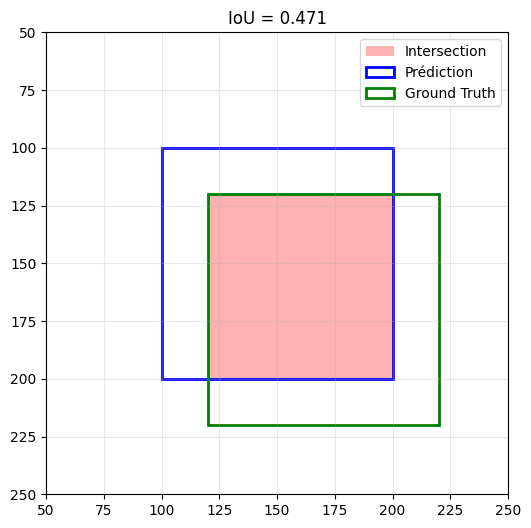

In [ ]:
# ═══════════════════════════════════════════════════════════
# FONCTION: Calcul de l'IoU
# ═══════════════════════════════════════════════════════════

def compute_iou(box1, box2):
    """
    Calcule l'IoU entre deux boxes

    Args:
        box1, box2: [x1, y1, x2, y2]

    Returns:
        iou: float (0 à 1)
    """
    # Coordonnées de l'intersection
    x1_inter = max(box1[0], box2[0])
    y1_inter = max(box1[1], box2[1])
    x2_inter = min(box1[2], box2[2])
    y2_inter = min(box1[3], box2[3])

    # Aire de l'intersection
    if x2_inter < x1_inter or y2_inter < y1_inter:
        intersection = 0  # Pas de chevauchement
    else:
        intersection = (x2_inter - x1_inter) * (y2_inter - y1_inter)

    # Aires des boxes
    area1 = (box1[2] - box1[0]) * (box1[3] - box1[1])
    area2 = (box2[2] - box2[0]) * (box2[3] - box2[1])

    # Union
    union = area1 + area2 - intersection

    # IoU
    iou = intersection / union if union > 0 else 0

    return iou

# ───────────────────────────────────────────────────────────
# EXEMPLE
# ───────────────────────────────────────────────────────────

# Box prédite
pred_box = [100, 100, 200, 200]  # 100×100 pixels

# Ground truth
gt_box = [120, 120, 220, 220]  # 100×100 pixels, décalée

# Calcul IoU
iou = compute_iou(pred_box, gt_box)
print(f"IoU: {iou:.3f}")
# IoU: 0.563

# Visualisation
import matplotlib.pyplot as plt
import matplotlib.patches as patches

fig, ax = plt.subplots(1, 1, figsize=(6, 6))

# Dessiner les boxes
rect_pred = patches.Rectangle((100, 100), 100, 100,
                               linewidth=2, edgecolor='blue',
                               facecolor='none', label='Prédiction')
rect_gt = patches.Rectangle((120, 120), 100, 100,
                             linewidth=2, edgecolor='green',
                             facecolor='none', label='Ground Truth')

# Zone d'intersection
rect_inter = patches.Rectangle((120, 120), 80, 80,
                                linewidth=0, facecolor='red',
                                alpha=0.3, label='Intersection')

ax.add_patch(rect_inter)
ax.add_patch(rect_pred)
ax.add_patch(rect_gt)

ax.set_xlim(50, 250)
ax.set_ylim(50, 250)
ax.set_aspect('equal')
ax.legend()
ax.set_title(f'IoU = {iou:.3f}')
plt.gca().invert_yaxis()
plt.grid(True, alpha=0.3)
plt.show()

#### LEADERBOARD & BEST MODEL EXPORT

In [ ]:
# Leaderboard recap + optional export of the best checkpoint
import shutil

if 'leaderboard_df' not in globals() or leaderboard_df.empty:
    raise RuntimeError(
        'leaderboard_df is empty. Run STEP 3 (full multi-checkpoint evaluation) first.'
    )

print('=' * 70)
print('LEADERBOARD RECAP')
print('=' * 70)
print(leaderboard_df.head(10).to_string(index=False))

if 'BEST_MODEL_PATH' not in globals():
    best_row = leaderboard_df.iloc[0]
    BEST_MODEL_PATH = Path(best_row['checkpoint_path'])
    BEST_MODEL_NAME = best_row['checkpoint_name']

print('\nBest checkpoint selected:')
print(f'  Name: {BEST_MODEL_NAME}')
print(f'  Path: {BEST_MODEL_PATH}')
print(f'  Selection metric ({SELECTION_METRIC}): {leaderboard_df.iloc[0][SELECTION_METRIC]:.3f}')

# Export/copy as final model
FINAL_MODEL_PATH = OUTPUTS_ROOT / 'model_final_best_auto.pth'
shutil.copy2(BEST_MODEL_PATH, FINAL_MODEL_PATH)

print('\nBest model copied as final model:')
print(f'  {FINAL_MODEL_PATH}')
print('\nYou can use FINAL_MODEL_PATH for deployment/inference.')

📂 Loading Cityscapes validation dataset...
✅ Dataset loaded successfully!
   Validation set: 492 images
   Classes: ['person', 'rider', 'car', 'truck', 'bus', 'train', 'motorcycle', 'bicycle']
   Number of classes: 8

🔧 Building model...


COCO Evaluator instantiated using config, this is deprecated behavior. Please pass in explicit arguments instead.
Using previously cached COCO format annotations at '/home/rachidjunior/VS_Code/INSEG_PRO/output_eval/cityscapes_custom_val_coco_format.json'. You need to clear the cache file if your dataset has been modified.


✅ Model loaded from: /home/rachidjunior/VS_Code/INSEG_PRO/outputs/mask_rcnn_cityscapes/model_final.pth

🔍 Creating evaluator for dataset: cityscapes_custom_val
🔍 Évaluation en cours sur 492 images...

Loading and preparing results...
DONE (t=0.01s)
creating index...
index created!
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.159
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.273
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.159
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.032
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.168
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.293
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.079
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.172
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.18

#### RESULTS INTERPRETATION

In [ ]:
# ═══════════════════════════════════════════════════════════
# CELL: Interpréter les Métriques
# ═══════════════════════════════════════════════════════════

def interpret_ap(ap_value):
    """
    Donne une interprétation humaine de l'AP
    """
    if ap_value >= 90:
        return "🟢 EXCELLENT - Niveau production"
    elif ap_value >= 75:
        return "🟡 BON - Utilisable avec attention"
    elif ap_value >= 50:
        return "🟠 MOYEN - Nécessite amélioration"
    else:
        return "🔴 FAIBLE - Réentraînement recommandé"

print("📊 DIAGNOSTIC:\n")

# Boxes
bbox_ap = bbox_results['AP']
print(f"Détection (Boxes): {bbox_ap:.1f}% {interpret_ap(bbox_ap)}")

# Masks
segm_ap = segm_results['AP']
print(f"Segmentation (Masks): {segm_ap:.1f}% {interpret_ap(segm_ap)}")

# Comparaison AP50 vs AP75
bbox_ap50 = bbox_results['AP50']
bbox_ap75 = bbox_results['AP75']
drop = bbox_ap50 - bbox_ap75

print(f"\n📉 Différence AP50 → AP75: {drop:.1f}%")
if drop > 15:
    print("  ⚠️ Grande chute → Boxes pas assez précises")
    print("  💡 Recommandation: Améliorer le box refinement")
else:
    print("  ✅ Boxes bien alignées!")

# Comparaison par taille
if bbox_results['APl'] > bbox_results['APm'] + 15:
    print("\n⚠️ Objets moyens détectés moins bien que les grands")
    print("💡 Recommandation: Ajuster les anchor sizes")

📊 DIAGNOSTIC:

Détection (Boxes): 15.9% 🔴 FAIBLE - Réentraînement recommandé
Segmentation (Masks): 13.5% 🔴 FAIBLE - Réentraînement recommandé

📉 Différence AP50 → AP75: 11.4%
  ✅ Boxes bien alignées!


#### METRICS VISUALIZATION

In [ ]:
# ═══════════════════════════════════════════════════════════
# CELL: Visualiser les Métriques
# ═══════════════════════════════════════════════════════════

import matplotlib.pyplot as plt
import numpy as np

# Données
categories = ['AP', 'AP50', 'AP75']
bbox_scores = [bbox_results['AP'], bbox_results['AP50'], bbox_results['AP75']]
segm_scores = [segm_results['AP'], segm_results['AP50'], segm_results['AP75']]

x = np.arange(len(categories))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

bars1 = ax.bar(x - width/2, bbox_scores, width, label='Bounding Boxes', color='#3498db')
bars2 = ax.bar(x + width/2, segm_scores, width, label='Segmentation', color='#e74c3c')

ax.set_ylabel('Average Precision (%)')
ax.set_title('Performance du Modèle (COCO Metrics)')
ax.set_xticks(x)
ax.set_xticklabels(categories)
ax.legend()
ax.set_ylim(0, 100)
ax.grid(axis='y', alpha=0.3)

# Ajouter les valeurs au-dessus des barres
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.1f}%',
                ha='center', va='bottom')

plt.tight_layout()
plt.savefig('./output_eval/metrics_comparison.png')
plt.show()